# Chapitre 18 - Problèmes en grande dimension ($p \gg N$)
## Cours 3 : ACP supervisée, tests multiples et taux de fausses découvertes

Plan (sections 18.6 et 18.7 du livre) :

1. **composantes principales supervisées** : régression en grande dimension via une
   variable latente ; comparaison avec la PLS, et « pré-conditionnement » du lasso ;
2. **évaluation des variables** et problème des **tests multiples** : FWER, Bonferroni,
   taux de fausses découvertes (FDR), procédure de **Benjamini-Hochberg**, estimation
   « plug-in » par permutations, procédure **SAM**, interprétation bayésienne.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl import ch18_grande_dimension as g

## 1. Composantes principales supervisées (section 18.6)

### 1.1 Le modèle à variable latente

Le livre motive la méthode par un exemple de survie (lymphomes) : on imagine deux
« types cellulaires » ; les patients du bon type vivent plus longtemps en moyenne.
Le type cellulaire n'est pas observé, mais il se reflète dans l'expression de tout un
**groupe** de gènes (une voie biologique). Formellement (éq. (18.32)-(18.33)) :
$$Y = \beta_0 + \beta_1 U + \varepsilon, \qquad X_j = \alpha_{0j} + \alpha_{1j}U + \epsilon_j,\quad j\in\mathcal P,$$
où $U$ est une **variable latente** (le « type cellulaire » continu), $\mathcal P$
l'ensemble des gènes de la voie, et les autres gènes $X_k$, $k\notin\mathcal P$, sont
indépendants de $U$. Les erreurs sont centrées et indépendantes de tout le reste.

> **Intuition.** Chaque gène de $\mathcal P$ est une **mesure bruitée** de $U$. En
> moyennant beaucoup de ces mesures (c'est ce que fait la première composante
> principale de $\mathbf X_{\mathcal P}$), on estime $U$ bien mieux qu'avec un seul gène,
> puis on régresse $Y$ sur cette estimation.

### 1.2 L'algorithme (algorithme 18.1)

1. Pour chaque variable $j$, calculer le coefficient de régression **univarié
   standardisé** de $y$ sur $x_j$ (une statistique $t$).
2. Pour chaque seuil $\theta$ d'une grille $0\le\theta_1<\dots<\theta_K$ :
   - (a) ne garder que les variables dont $|$score$| > \theta$ et calculer les $m$
     premières composantes principales de cette matrice réduite ;
   - (b) utiliser ces composantes dans un modèle de régression pour prédire $y$.
3. Choisir $\theta$ (et $m$) par validation croisée.

Lien avec le modèle latent : l'étape 1 estime $\mathcal P$, l'étape 2a estime $U$, et
l'étape 2b estime $\beta_0,\beta_1$. Le plus souvent $m = 1$.

### 1.3 La simulation du livre (éq. (18.37))

$N = 100$ échantillons, $p = 5000$ gènes ; $\epsilon_{ij}\sim\mathcal N(0,1)$ et
$\varepsilon_i\sim\mathcal N(0, 1.5^2)$ :

- gènes $1$ à $50$ : moyenne $3$ pour les échantillons $1$–$50$, $4$ pour $51$–$100$ ;
- gènes $51$ à $250$ : moyenne $1.5$ pour les échantillons $1$–$25$ et $51$–$75$,
  $5.5$ pour les autres ;
- gènes $251$ à $5000$ : bruit pur ;
- $y_i = 2\cdot\frac1{50}\sum_{j=1}^{50}x_{ij} + \varepsilon_i$.

Les 50 premiers gènes portent un écart modéré **lié à $y$** ; les 200 suivants un écart
**beaucoup plus grand** (4 unités) mais **sans lien** avec $y$.

In [2]:
def simulate_spca(rng, N=100, p=5000):
    """Un jeu de données du modèle (18.37)."""
    X = rng.randn(N, p)
    i = np.arange(N)
    X[:, :50] += np.where(i < 50, 3.0, 4.0)[:, None]
    X[:, 50:250] += np.where((i % 50) < 25, 1.5, 5.5)[:, None]
    y = 2 * X[:, :50].mean(1) + 1.5 * rng.randn(N)
    return X, y


rng = np.random.RandomState(0)
X_s, y_s = simulate_spca(rng)

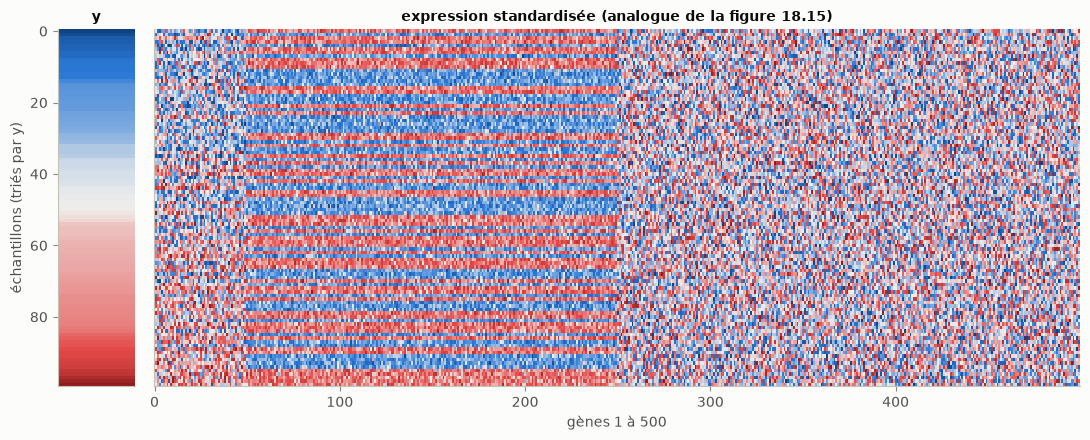

In [3]:
order_rows = np.argsort(y_s)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1, 12]})
axes[0].imshow(y_s[order_rows][:, None], aspect="auto", cmap=DIV, interpolation="nearest")
axes[0].set_xticks([])
axes[0].set_ylabel("échantillons (triés par y)")
axes[0].set_title("y", fontsize=10)
Xshow = X_s[order_rows][:, :500]
Xshow = (Xshow - Xshow.mean(0)) / Xshow.std(0)
axes[1].imshow(Xshow, aspect="auto", cmap=DIV, vmin=-2.5, vmax=2.5, interpolation="nearest")
axes[1].set_xlabel("gènes 1 à 500")
axes[1].set_yticks([])
axes[1].set_title("expression standardisée (analogue de la figure 18.15)", fontsize=10)
for ax in axes:
    ax.grid(False)
plt.tight_layout()
plt.show()

Les gènes 51–250 (au centre) dessinent un motif très visible (deux groupes
d'échantillons alternés) mais sans rapport avec $y$ ; les gènes 1–50 (à gauche)
suivent faiblement l'ordre de $y$.

**Pourquoi l'ACP ordinaire échoue.** La première composante principale cherche la
direction de **plus grande variance** : ici celle des gènes 51–250 (écart de 4 unités
sur 200 gènes). Elle n'a rien à voir avec $y$. La sélection supervisée (étape 1)
élimine ces gènes avant de calculer la composante.

In [4]:
sc = g.univariate_scores(X_s, y_s)
Xc = X_s - X_s.mean(0)
pc1_all = Xc @ np.linalg.svd(Xc, full_matrices=False)[2][0]
spca = g.SupervisedPCA(n_features=50).fit(X_s, y_s, scores=sc)
pc1_sup = spca.transform(X_s)[:, 0]
print("gènes retenus parmi les 50 vrais :", np.sum(spca.selected_ < 50), "/ 50")
print(f"corrélation(y, CP1 de tous les gènes)        = {abs(np.corrcoef(y_s, pc1_all)[0, 1]):.2f}")
print(f"corrélation(y, CP1 supervisée, 50 gènes)     = {abs(np.corrcoef(y_s, pc1_sup)[0, 1]):.2f}")

gènes retenus parmi les 50 vrais : 28 / 50
corrélation(y, CP1 de tous les gènes)        = 0.08
corrélation(y, CP1 supervisée, 50 gènes)     = 0.68


### 1.4 Lien avec les moindres carrés partiels (PLS)

On suppose les variables standardisées. La première variable PLS (section 3.5.2)
restreinte aux variables sélectionnées est (éq. (18.34))
$z = \sum_{j\in\mathcal P}\langle y, x_j\rangle\,x_j$ : chaque gène est pondéré par sa
covariance avec $y$ (« PLS seuillée »). La composante supervisée $\hat u$ vérifie au
contraire (éq. (18.35))
$$\hat u = \frac1{d^2}\sum_{j\in\mathcal P}\langle\hat u, x_j\rangle\,x_j ,$$
où $d$ est la plus grande valeur singulière de $\mathbf X_{\mathcal P}$.

**Démonstration de (18.35).** Soit $\mathbf X_{\mathcal P} = \mathbf U\mathbf D\mathbf V^T$
et $\hat u = u_1$ la première colonne de $\mathbf U$ (composante normalisée). Par
définition de la SVD, $\mathbf X_{\mathcal P}\mathbf X_{\mathcal P}^T u_1 = d^2u_1$. Or
$\mathbf X_{\mathcal P}\mathbf X_{\mathcal P}^T = \sum_{j\in\mathcal P}x_jx_j^T$ (somme
sur les colonnes), donc
$d^2 u_1 = \sum_j x_j(x_j^Tu_1) = \sum_j\langle u_1, x_j\rangle x_j$. $\square$

Les poids de la PLS dépendent du seul $y$ (bruité) ; ceux de $\hat u$ sont
**auto-cohérents** et s'appuient sur tous les gènes de $\mathcal P$ : on peut montrer
(éq. (18.36)) que $z = u + O_p(1)$ alors que $\hat u = u + O_p(\sqrt{p_1/N})$.

### 1.5 Erreurs de test (figure 18.16)

On répète la simulation (20 fois, au lieu de 100 dans le livre, pour limiter le temps
de calcul) ; pour chaque nombre de variables retenues, on mesure la racine de l'erreur
quadratique moyenne de test, divisée par l'écart-type du bruit ($1.5$, l'erreur de
Bayes vaut donc 1). Le dernier point (5000 variables) correspond à l'ACP et à la PLS
ordinaires.

In [5]:
def thresholded_pls(X, y, sel, Xte):
    """PLS à une composante sur les variables sel (standardisées) ; prédiction sur Xte."""
    mu, sd = X[:, sel].mean(0), X[:, sel].std(0)
    Z, Zt = (X[:, sel] - mu) / sd, (Xte[:, sel] - mu) / sd
    yc = y - y.mean()
    w = Z.T @ yc                      # poids <y, x_j>
    z, zt = Z @ w, Zt @ w
    return y.mean() + zt * (z @ yc) / (z @ z)


n_feat = [10, 25, 50, 100, 150, 200, 250, 300, 5000]
rng = np.random.RandomState(1)
err_spca, err_pls = [], []
for _ in range(20):
    X, y = simulate_spca(rng)
    Xt, yt = simulate_spca(rng)
    s = g.univariate_scores(X, y)
    order = np.argsort(-np.abs(s))
    e1, e2 = [], []
    for k in n_feat:
        m = g.SupervisedPCA(n_features=k).fit(X, y, scores=s)
        e1.append(np.sqrt(np.mean((m.predict(Xt) - yt) ** 2)) / 1.5)
        e2.append(np.sqrt(np.mean((thresholded_pls(X, y, order[:k], Xt) - yt) ** 2)) / 1.5)
    err_spca.append(e1)
    err_pls.append(e2)
err_spca, err_pls = np.array(err_spca), np.array(err_pls)

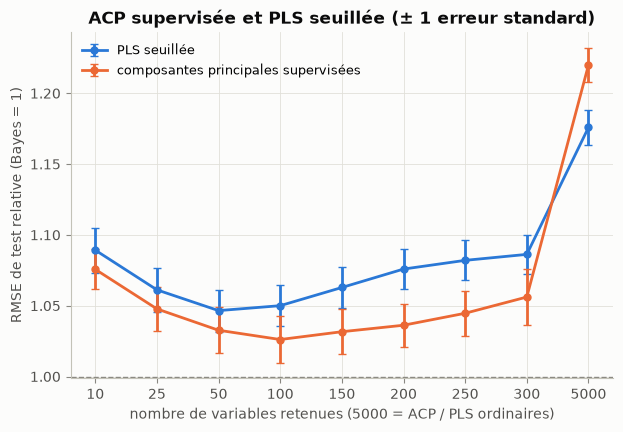

In [6]:
xpos = np.arange(len(n_feat))
fig, ax = plt.subplots(figsize=(7, 4.5))
for E, name, c in [(err_pls, "PLS seuillée", BLUE), (err_spca, "composantes principales supervisées", ORANGE)]:
    m, se = E.mean(0), E.std(0) / np.sqrt(len(E))
    ax.errorbar(xpos, m, yerr=se, fmt="o-", color=c, capsize=3, label=name)
ax.set_xticks(xpos, [str(k) for k in n_feat])
ax.axhline(1.0, color=GRAY, ls="--", lw=1)
ax.set_xlabel("nombre de variables retenues (5000 = ACP / PLS ordinaires)")
ax.set_ylabel("RMSE de test relative (Bayes = 1)")
ax.set_title("ACP supervisée et PLS seuillée (± 1 erreur standard)")
ax.legend()
plt.show()

Les deux méthodes seuillées font bien mieux que leurs versions sur tous les gènes
(point de droite), contaminées par les variables de bruit. Dès qu'on filtre, l'ACP
supervisée est meilleure que la PLS seuillée, avec un minimum entre 50 et 100
variables (il y a 50 gènes utiles). Sur tous les gènes, l'ACP ordinaire est la pire :
sa première composante est celle des gènes 51–250, sans lien avec $y$.

### 1.6 Pré-conditionnement du lasso (section 18.6.3)

L'ACP supervisée prédit bien mais ne donne pas un modèle **parcimonieux** en les
gènes. Le lasso est parcimonieux, mais souffre du bruit dans $y$ et des milliers de
variables inutiles. Le **pré-conditionnement** combine les deux :

1. calculer la prédiction $\hat y_i$ de l'ACP supervisée sur l'échantillon d'apprentissage ;
2. ajuster un lasso de $\hat y$ (réponse **débruitée**) sur **toutes** les variables.

In [7]:
rng = np.random.RandomState(5)
X, y = simulate_spca(rng)
Xt, yt = simulate_spca(rng)
mu, ym = X.mean(0), y.mean()
Xc, Xtc = X - mu, Xt - mu

y_hat = g.SupervisedPCA(n_features=50).fit(X, y).predict(X)
paths = {}
for target, name in [(y, "lasso"), (y_hat, "lasso pré-conditionné")]:
    tc = target - target.mean()
    lam_max = np.max(np.abs(Xc.T @ tc))
    lams = lam_max * np.logspace(0, -2.5, 30)
    P = g.lasso_path(Xc, tc, lams, tol=1e-5, n_iter=500)
    paths[name] = ((P != 0).sum(1), [np.mean((ym + Xtc @ b - yt) ** 2) for b in P])

spca_k = [5, 10, 25, 50, 100, 150, 200, 250]
spca_err = [np.mean((g.SupervisedPCA(n_features=k).fit(X, y).predict(Xt) - yt) ** 2) for k in spca_k]

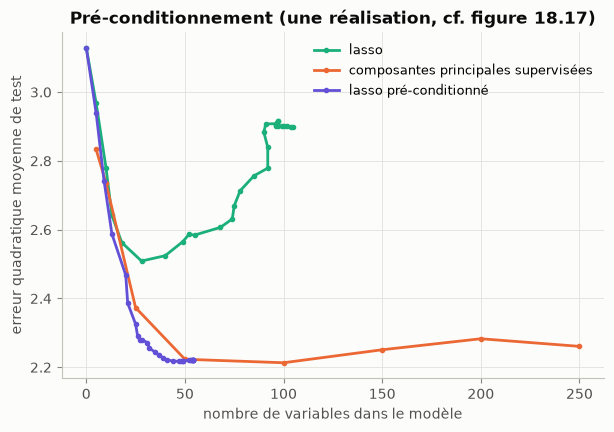

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(*paths["lasso"], "o-", ms=3, color=COLORS[2], label="lasso")
ax.plot(spca_k, spca_err, "o-", ms=3, color=ORANGE, label="composantes principales supervisées")
ax.plot(*paths["lasso pré-conditionné"], "o-", ms=3, color=COLORS[6], label="lasso pré-conditionné")
ax.set_xlabel("nombre de variables dans le modèle")
ax.set_ylabel("erreur quadratique moyenne de test")
ax.set_title("Pré-conditionnement (une réalisation, cf. figure 18.17)")
ax.legend()
plt.show()

Le lasso ordinaire commence à sur-ajuster tôt et s'arrête vers $N = 100$ variables.
Le lasso pré-conditionné, appliqué à la réponse débruitée, atteint l'erreur de l'ACP
supervisée avec un **petit** nombre de gènes et ne sur-ajuste pas : il combine
précision et parcimonie.

> **À retenir.** L'ACP supervisée filtre d'abord les variables par leur lien
> univarié avec $y$, puis résume les variables retenues par leur première composante
> principale (estimation d'un facteur latent). Le pré-conditionnement fournit ensuite
> un modèle parcimonieux.

## 2. Évaluation des variables et tests multiples (section 18.7)

Souvent, le but n'est pas de prédire mais d'**identifier** les variables (gènes,
protéines…) qui diffèrent entre deux groupes. Pour la suite on note $M$ (et non $p$)
le nombre de variables, la lettre $p$ étant réservée aux $p$-valeurs.

### 2.1 Les données

Le livre utilise une étude de sensibilité aux radiations (tableau 18.4) : $M = 12\,625$
gènes, 44 patients « normaux » et 14 « sensibles ». Ces données n'étant pas
disponibles hors ligne, nous **simulons** un jeu de même taille, où nous connaissons
la vérité : 250 gènes (2 %) sont plus exprimés chez les patients sensibles (écart
entre 0.4 et 1.4 écart-type), tous les autres sont nuls. Les échelles diffèrent d'un
gène à l'autre, comme pour de vraies mesures.

In [9]:
rng = np.random.RandomState(0)
M, N1, N2, M1 = 12625, 44, 14, 250
scale = np.exp(rng.randn(M))
Xr = rng.randn(N1 + N2, M) * scale
sensitive = np.r_[np.zeros(N1, bool), np.ones(N2, bool)]
is_alt = np.zeros(M, bool)
is_alt[rng.choice(M, M1, replace=False)] = True
Xr[np.ix_(sensitive, is_alt)] += rng.uniform(0.4, 1.4, M1) * scale[is_alt]
print("données :", Xr.shape, "- gènes réellement différentiels :", is_alt.sum())

données : (58, 12625) - gènes réellement différentiels : 250


### 2.2 Statistiques $t$ et distribution de permutation

Pour chaque gène, la **statistique $t$ à deux échantillons** (éq. (18.38)-(18.39)) :
$$t_j = \frac{\bar x_{2j} - \bar x_{1j}}{\mathrm{se}_j},\qquad
  \mathrm{se}_j = \hat\sigma_j\sqrt{\frac1{N_1}+\frac1{N_2}},\qquad
  \hat\sigma_j^2 = \frac1{N_1+N_2-2}\Big(\sum_{i\in C_1}(x_{ij}-\bar x_{1j})^2 + \sum_{i\in C_2}(x_{ij}-\bar x_{2j})^2\Big).$$
Sous l'hypothèse nulle et pour des données gaussiennes, $t_j$ suit une loi de Student
à $N_1+N_2-2$ degrés de liberté. Pour éviter l'hypothèse gaussienne, on utilise la
**distribution de permutation** : on permute aléatoirement les étiquettes de groupe
$K = 1000$ fois et l'on recalcule les statistiques $t_j^k$.

In [10]:
t_obs = g.t_statistics(Xr, sensitive)
t_perm = g.permutation_t(Xr, sensitive, 1000, np.random.RandomState(1))
print("t_perm :", t_perm.shape)

t_perm : (1000, 12625)


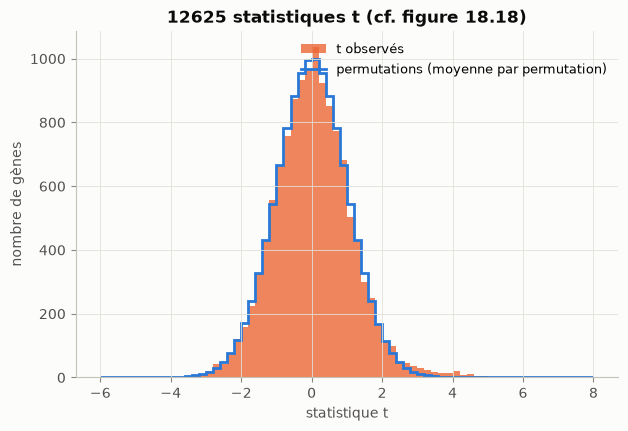

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(-6, 8, 71)
ax.hist(t_obs, bins=bins, color=ORANGE, alpha=0.8, label="t observés")
null_counts, _ = np.histogram(t_perm.ravel(), bins=bins)
ax.stairs(null_counts / t_perm.shape[0], bins, color=BLUE, lw=2,
          label="permutations (moyenne par permutation)")
ax.set_xlabel("statistique t")
ax.set_ylabel("nombre de gènes")
ax.set_title(f"{M} statistiques t (cf. figure 18.18)")
ax.legend()
plt.show()

L'histogramme observé suit la distribution de permutation, sauf un excès de grandes
valeurs positives : les gènes différentiels. Mais **lesquels** ?

In [12]:
n_big = np.sum(np.abs(t_obs) >= 2)
q = 2 * stats.t.sf(2, N1 + N2 - 2)
print(f"gènes avec |t| >= 2 : {n_big}")
print(f"sous l'hypothèse « aucun effet » et gènes indépendants : nombre ~ Binomiale(M, {q:.3f}),"
      f" moyenne {M * q:.0f}, écart-type {np.sqrt(M * q * (1 - q)):.0f}")

gènes avec |t| >= 2 : 820
sous l'hypothèse « aucun effet » et gènes indépendants : nombre ~ Binomiale(M, 0.050), moyenne 636, écart-type 25


Au seuil naïf $|t|\ge 2$ (niveau $\approx 5\,\%$ par test), on s'attend à environ 640
faux positifs **même si aucun gène n'était différentiel** : la liste obtenue est
majoritairement composée de fausses découvertes. C'est le **problème des tests
multiples**.

### 2.3 $p$-valeurs par permutation

Pour le gène $j$, la $p$-valeur de permutation (éq. (18.40)) est
$p_j = \frac1K\sum_k\mathbb 1(|t_j^k| > |t_j|)$. Comme tous les gènes sont sur une
échelle comparable (les $t$ sont sans dimension), on peut **mettre en commun** les
$MK$ valeurs nulles (éq. (18.41)) :
$$p_j = \frac1{MK}\sum_{j'=1}^M\sum_{k=1}^K\mathbb 1(|t_{j'}^k| > |t_j|),$$
ce qui donne des $p$-valeurs beaucoup plus fines (résolution $1/(MK)\approx 8\cdot10^{-8}$).

In [ ]:
pvals = g.pooled_permutation_pvalues(t_obs, t_perm)
p_student = 2 * stats.t.sf(np.abs(t_obs), N1 + N2 - 2)
print("plus petites p-valeurs (permutation poolée) :", np.sort(pvals)[:5])
print("corrélation des log p-valeurs permutation / Student :",
      np.corrcoef(np.log(pvals + 1e-9), np.log(p_student))[0, 1].round(3))

### 2.4 Erreur de type I globale : FWER et Bonferroni

On teste $H_{0j}$ : « pas d'effet sur le gène $j$ », $j = 1,\dots,M$ (éq. (18.42)),
en rejetant si $p_j < \alpha$. Soit $A_j$ l'événement « $H_{0j}$ est rejetée à tort » et
$A = \bigcup_j A_j$. Le **taux d'erreur familial** (FWER) est $\Pr(A)$, la probabilité
d'au moins un faux positif. Pour $M_0$ tests nuls indépendants de niveau $\alpha$ :
$\Pr(A) = 1-(1-\alpha)^{M_0}$, qui tend vers 1 très vite.

**Bonferroni** : rejeter si $p_j < \alpha/M$. Par la sous-additivité des probabilités,
$\Pr(A)\le\sum_j\Pr(A_j)\le M\cdot\alpha/M = \alpha$ (exercice 18.16).

In [ ]:
alpha = 0.05
rej_bonf = g.bonferroni(pvals, alpha)
print(f"seuil de Bonferroni : {alpha / M:.1e}  ->  {rej_bonf.sum()} gènes rejetés "
      f"(dont {np.sum(rej_bonf & ~is_alt)} faux positifs)")
print("FWER de 1000 tests indépendants de niveau 0.05 :", round(1 - 0.95 ** 1000, 6))

Bonferroni contrôle le FWER mais est **très conservateur** quand $M$ est grand : il
ne retrouve qu'une petite partie des 250 gènes différentiels.

### 2.5 Le taux de fausses découvertes (FDR)

Résumé des $M$ tests (tableau 18.5) :

| | non significatif | significatif | total |
|---|---|---|---|
| $H_0$ vraie | $U$ | $V$ | $M_0$ |
| $H_0$ fausse | $T$ | $S$ | $M_1$ |
| total | $M - R$ | $R$ | $M$ |

$V$ est le nombre de **faux positifs**, $R$ le nombre de rejets. Le FWER vaut
$\Pr(V\ge 1)$. Le **taux de fausses découvertes** (éq. (18.43)) est
$$\mathrm{FDR} = \mathbb E\Big(\frac VR\Big)\qquad(\text{avec } V/R = 0 \text{ si } R = 0),$$
la proportion **attendue** de faux positifs parmi les gènes déclarés significatifs.
Pour un biologiste qui reçoit une liste de gènes, c'est une mesure très parlante.